In [24]:
!pip install -q scikit-learn imbalanced-learn xgboost lightgbm kaggle


In [25]:
from google.colab import files
uploaded = files.upload()

Saving kaggle (1).json to kaggle (1) (1).json


**Kaggle key setup**

In [26]:
import os
os.makedirs('/root/.kaggle', exist_ok=True)
!cp "kaggle (1).json" /root/.kaggle/kaggle.json
!chmod 600 /root/.kaggle/kaggle.json

In [27]:
!kaggle datasets download -d mlg-ulb/creditcardfraud -p /content/data/ulb --unzip
!kaggle datasets download -d kartik2112/fraud-detection -p /content/data/sparkov --unzip

Dataset URL: https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud
License(s): DbCL-1.0
100% 66.0M/66.0M [00:00<00:00, 149MB/s]

Dataset URL: https://www.kaggle.com/datasets/kartik2112/fraud-detection
License(s): CC0-1.0
100% 202M/202M [00:02<00:00, 98.9MB/s]



In [28]:
import pandas as pd

ulb = pd.read_csv('/content/data/ulb/creditcard.csv')
print("ULB shape:", ulb.shape)
ulb.head()

ULB shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [29]:
print("Missing values per column:")
print(ulb.isnull().sum())
print("\nDuplicate rows:", ulb.duplicated().sum())

Missing values per column:
Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

Duplicate rows: 1081


ULB — Data Quality: No missing values found across all 31 columns. 1,081 exact duplicate rows detected out of 284,807 — these are dropped in the next step, since identical rows across all features are almost certainly a data export artifact rather than genuine repeat transactions.

In [30]:
ulb_clean = ulb.drop_duplicates()
print("Before:", ulb.shape, " After:", ulb_clean.shape)

Before: (284807, 31)  After: (283726, 31)


In [31]:
print(ulb_clean['Class'].value_counts())
fraud_rate_ulb = ulb_clean['Class'].mean() * 100
print(f"\nFraud rate: {fraud_rate_ulb:.4f}%")
print(f"Imbalance ratio (legit:fraud) = {(1-ulb_clean['Class'].mean())/ulb_clean['Class'].mean():.1f} : 1")

Class
0    283253
1       473
Name: count, dtype: int64

Fraud rate: 0.1667%
Imbalance ratio (legit:fraud) = 598.8 : 1


ULB — Class Imbalance: After cleaning, 473 fraud transactions out of 283,726 total — a fraud rate of 0.1667%, or roughly 599 legitimate transactions for every 1 fraudulent one. This confirms accuracy is not a usable metric here, since a model predicting "not fraud" every time would score 99.83% while catching zero fraud.

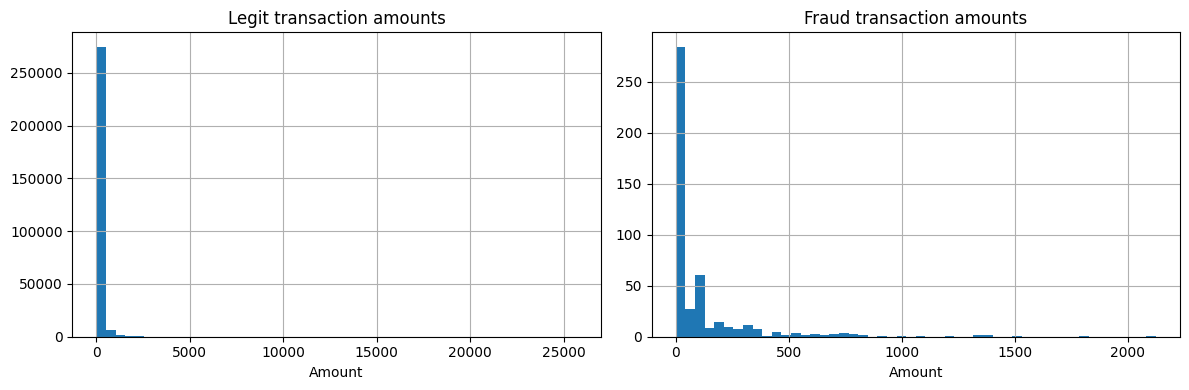

In [32]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12,4))

ulb_clean[ulb_clean['Class']==0]['Amount'].hist(bins=50, ax=axes[0])
axes[0].set_title('Legit transaction amounts')
axes[0].set_xlabel('Amount')

ulb_clean[ulb_clean['Class']==1]['Amount'].hist(bins=50, ax=axes[1])
axes[1].set_title('Fraud transaction amounts')
axes[1].set_xlabel('Amount')

plt.tight_layout()
plt.show()

ULB — Amount Distribution: Fraud transactions are almost entirely capped under ~$2,000, while legitimate transactions range up to $25,000+. This suggests fraudsters deliberately avoid large transactions that could trigger manual review, making Amount a potentially useful feature even before any spatial-temporal engineering.

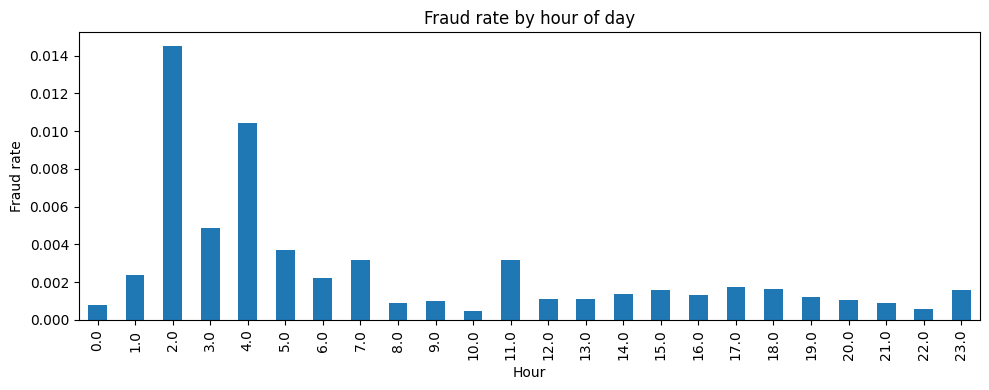

In [33]:
ulb_clean = ulb_clean.copy()
ulb_clean['Hour'] = (ulb_clean['Time'] // 3600) % 24

hourly_fraud = ulb_clean.groupby('Hour')['Class'].mean()
hourly_fraud.plot(kind='bar', figsize=(10,4))
plt.ylabel('Fraud rate')
plt.title('Fraud rate by hour of day')
plt.tight_layout()
plt.show()

ULB — Time Pattern: Fraud rate spikes sharply at hour 2  and hour 4 , compared to a baseline of ~0.05-0.1% during normal hours — roughly 3-7x higher risk overnight. This is the first evidence supporting the project's temporal-feature premise.

In [34]:
sparkov = pd.read_csv('/content/data/sparkov/fraudTrain.csv')
print("Sparkov shape:", sparkov.shape)
sparkov.head()

Sparkov shape: (1296675, 23)


,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,...,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0
1,1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,...,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0
2,2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,...,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0
3,3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,...,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0
4,4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,...,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0


In [35]:
print("Missing values per column:")
print(sparkov.isnull().sum())
print("\nDuplicate rows:", sparkov.duplicated().sum())

Missing values per column:
Unnamed: 0               0
trans_date_trans_time    0
cc_num                   0
merchant                 0
category                 0
amt                      0
first                    0
last                     0
gender                   0
street                   0
city                     0
state                    0
zip                      0
lat                      0
long                     0
city_pop                 0
job                      0
dob                      0
trans_num                0
unix_time                0
merch_lat                0
merch_long               0
is_fraud                 0
dtype: int64

Duplicate rows: 0


Sparkov — Data Quality: No missing values, no duplicate rows across all 1,296,675 transactions — cleaner than ULB, no preprocessing needed at this stage.

In [36]:
print(sparkov['is_fraud'].value_counts())
fraud_rate_sparkov = sparkov['is_fraud'].mean() * 100
print(f"\nFraud rate: {fraud_rate_sparkov:.4f}%")
print(f"Imbalance ratio (legit:fraud) = {(1-sparkov['is_fraud'].mean())/sparkov['is_fraud'].mean():.1f} : 1")

is_fraud
0    1289169
1       7506
Name: count, dtype: int64

Fraud rate: 0.5789%
Imbalance ratio (legit:fraud) = 171.8 : 1


Sparkov — Class Imbalance: 7,506 fraud out of 1,296,675 total — a fraud rate of 0.5789%, roughly 172:1. This is notably less imbalanced than ULB (599:1), meaning imbalance-handling techniques may show different effect sizes across the two datasets in Week 6.

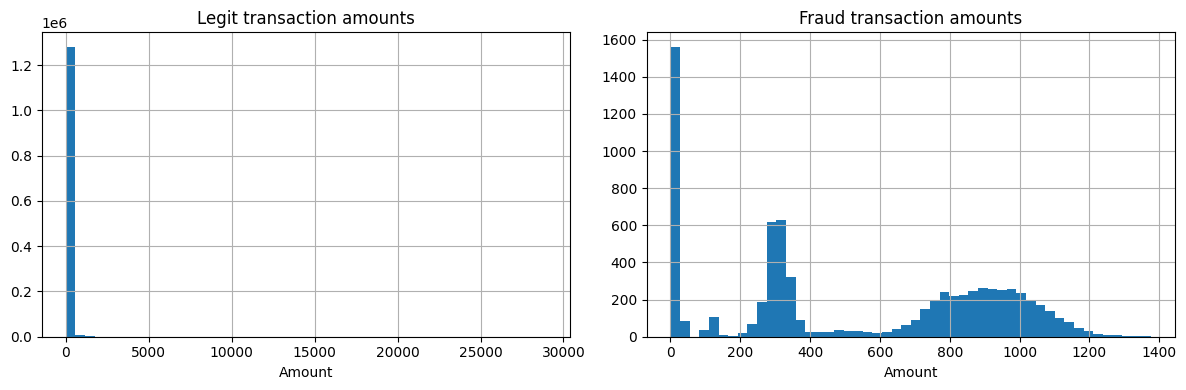

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))

sparkov[sparkov['is_fraud']==0]['amt'].hist(bins=50, ax=axes[0])
axes[0].set_title('Legit transaction amounts')
axes[0].set_xlabel('Amount')

sparkov[sparkov['is_fraud']==1]['amt'].hist(bins=50, ax=axes[1])
axes[1].set_title('Fraud transaction amounts')
axes[1].set_xlabel('Amount')

plt.tight_layout()
plt.show()

Sparkov — Amount Distribution: Fraud amounts show a multi-modal distribution — distinct clusters near $0, ~$300, and $700-1000 — unlike ULB's single tight cluster near zero. This suggests multiple distinct fraud behaviors may be present in this dataset rather than one fraud "type."

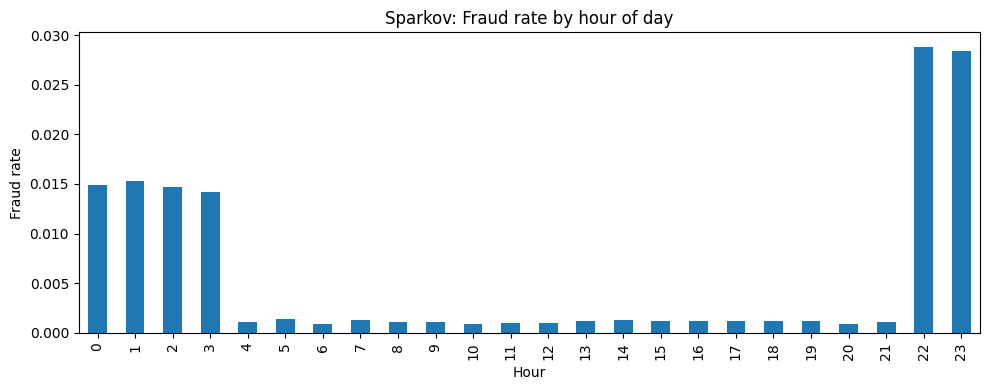

In [38]:
sparkov['trans_date_trans_time'] = pd.to_datetime(sparkov['trans_date_trans_time'])
sparkov['Hour'] = sparkov['trans_date_trans_time'].dt.hour

hourly_fraud_sparkov = sparkov.groupby('Hour')['is_fraud'].mean()
hourly_fraud_sparkov.plot(kind='bar', figsize=(10,4))
plt.ylabel('Fraud rate')
plt.title('Sparkov: Fraud rate by hour of day')
plt.tight_layout()
plt.show()

Sparkov — Time Pattern: Fraud rate is elevated from 10 PM to 3 AM (~1.4-2.9%), compared to ~0.1% during the day — a wider overnight window than ULB, but the same directional pattern. This cross-dataset consistency, across one real and one synthetic dataset, gives strong confidence that time-of-day is a genuine fraud signal.

In [39]:
print(sparkov[['lat','long','merch_lat','merch_long']].describe())

                lat          long     merch_lat    merch_long
count  1.296675e+06  1.296675e+06  1.296675e+06  1.296675e+06
mean   3.853762e+01 -9.022634e+01  3.853734e+01 -9.022646e+01
std    5.075808e+00  1.375908e+01  5.109788e+00  1.377109e+01
min    2.002710e+01 -1.656723e+02  1.902779e+01 -1.666712e+02
25%    3.462050e+01 -9.679800e+01  3.473357e+01 -9.689728e+01
50%    3.935430e+01 -8.747690e+01  3.936568e+01 -8.743839e+01
75%    4.194040e+01 -8.015800e+01  4.195716e+01 -8.023680e+01
max    6.669330e+01 -6.795030e+01  6.751027e+01 -6.695090e+01


Sparkov — Geo Data Check: Cardholder and merchant coordinates both fall within sensible real-world US ranges, with no broken or missing values — confirming the geo fields are usable for distance-based feature engineering.

In [40]:
import numpy as np

def haversine_distance(lat1, lon1, lat2, lon2):
    """Calculate distance in km between two lat/long points"""
    R = 6371  # Earth's radius in km
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2)**2
    c = 2 * np.arcsin(np.sqrt(a))
    return R * c

sparkov['distance_km'] = haversine_distance(
    sparkov['lat'], sparkov['long'],
    sparkov['merch_lat'], sparkov['merch_long']
)

print(sparkov['distance_km'].describe())

count    1.296675e+06
mean     7.611465e+01
std      2.911693e+01
min      2.225452e-02
25%      5.533491e+01
50%      7.823175e+01
75%      9.850327e+01
max      1.521172e+02
Name: distance_km, dtype: float64


In [41]:
print("Median distance - Legit:", sparkov[sparkov['is_fraud']==0]['distance_km'].median())
print("Median distance - Fraud:", sparkov[sparkov['is_fraud']==1]['distance_km'].median())

print("\nMean distance - Legit:", sparkov[sparkov['is_fraud']==0]['distance_km'].mean())
print("Mean distance - Fraud:", sparkov[sparkov['is_fraud']==1]['distance_km'].mean())

Median distance - Legit: 78.23301215383945
Median distance - Fraud: 77.93195445765167

Mean distance - Legit: 76.11375583007313
Mean distance - Fraud: 76.268329626882


Sparkov — Spatial Finding #1: Median distance-from-home is nearly identical between fraud (77.93 km) and legitimate (78.23 km) transactions, and the means are equally close (76.27 km vs. 76.11 km). Raw distance-from-home does not appear to separate fraud from legitimate transactions in this dataset.

In [42]:
# Sort by user (cc_num) and time, so consecutive rows = consecutive transactions per user
sparkov_sorted = sparkov.sort_values(['cc_num', 'trans_date_trans_time']).copy()

# Get previous transaction's merchant lat/long for the same user
sparkov_sorted['prev_merch_lat'] = sparkov_sorted.groupby('cc_num')['merch_lat'].shift(1)
sparkov_sorted['prev_merch_long'] = sparkov_sorted.groupby('cc_num')['merch_long'].shift(1)

# Calculate distance between current and previous transaction location
sparkov_sorted['dist_from_prev_txn_km'] = haversine_distance(
    sparkov_sorted['merch_lat'], sparkov_sorted['merch_long'],
    sparkov_sorted['prev_merch_lat'], sparkov_sorted['prev_merch_long']
)

print(sparkov_sorted['dist_from_prev_txn_km'].describe())

count    1.295692e+06
mean     1.035944e+02
std      5.039868e+01
min      8.069198e-02
25%      6.438102e+01
50%      1.007818e+02
75%      1.397061e+02
max      2.859922e+02
Name: dist_from_prev_txn_km, dtype: float64


In [43]:
print("Median dist-from-prev - Legit:", sparkov_sorted[sparkov_sorted['is_fraud']==0]['dist_from_prev_txn_km'].median())
print("Median dist-from-prev - Fraud:", sparkov_sorted[sparkov_sorted['is_fraud']==1]['dist_from_prev_txn_km'].median())

print("\nMean dist-from-prev - Legit:", sparkov_sorted[sparkov_sorted['is_fraud']==0]['dist_from_prev_txn_km'].mean())
print("Mean dist-from-prev - Fraud:", sparkov_sorted[sparkov_sorted['is_fraud']==1]['dist_from_prev_txn_km'].mean())

Median dist-from-prev - Legit: 100.78884849726494
Median dist-from-prev - Fraud: 99.59433978357941

Mean dist-from-prev - Legit: 103.59362863341438
Mean dist-from-prev - Fraud: 103.73219363282891


Sparkov — Spatial Finding #2: Distance between a user's consecutive transactions also shows no meaningful difference (fraud median 99.59 km vs. legit 100.79 km). Combined with Finding #1, this suggests Sparkov's synthetic fraud generation may not model geographic clustering the way real fraud rings do (as captured in STGN/STAN using real bank data) — worth validating against IEEE-CIS later, or exploring alternative spatial features (e.g., location diversity within a time window) in Week 5.

In [44]:
category_fraud = sparkov.groupby('category')['is_fraud'].mean().sort_values(ascending=False)
print(category_fraud)

category
shopping_net      0.017561
misc_net          0.014458
grocery_pos       0.014098
shopping_pos      0.007225
gas_transport     0.004694
misc_pos          0.003139
grocery_net       0.002948
travel            0.002864
entertainment     0.002478
personal_care     0.002424
kids_pets         0.002114
food_dining       0.001651
home              0.001608
health_fitness    0.001549
Name: is_fraud, dtype: float64


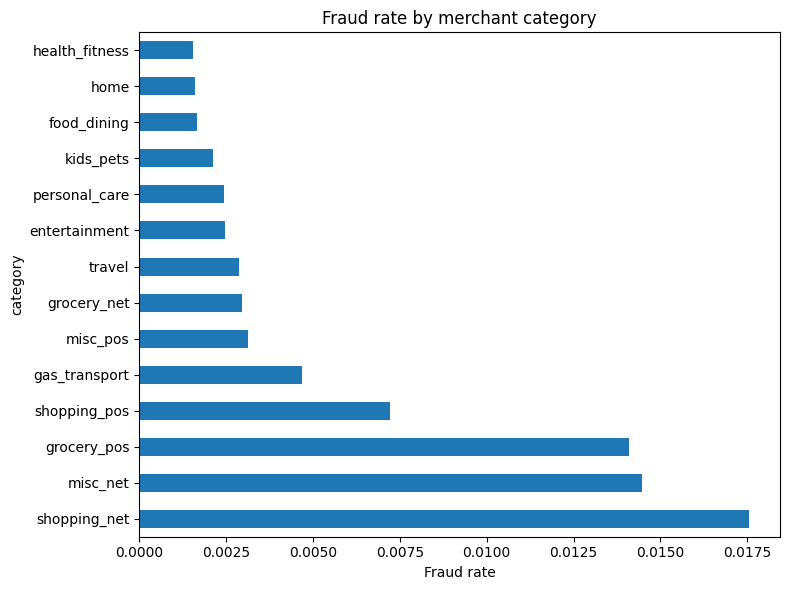

In [45]:
category_fraud.plot(kind='barh', figsize=(8,6))
plt.xlabel('Fraud rate')
plt.title('Fraud rate by merchant category')
plt.tight_layout()
plt.show()

Sparkov — Category Finding: Fraud rate varies substantially by category, from 0.15% (health_fitness) to 1.76% (shopping_net) — an ~11x spread. Online/card-not-present categories (_net) generally show higher fraud rates than in-person (_pos) equivalents (e.g., shopping_net 1.76% vs. shopping_pos 0.72%), consistent with reduced identity verification for card-not-present transactions. This is the strongest non-temporal signal found, and a validated candidate feature for Week 5 — especially given the flat spatial-distance findings above.

Primary Dataset Decision: ULB will be used for the naive baseline model (Week 4), since it is small, clean, and requires minimal preprocessing. Sparkov will be the primary dataset for feature engineering (Week 5+): despite showing no spatial-distance signal, it has strong temporal and category-level fraud signal, real geo-coordinates for further exploration, and a richer feature set overall than ULB.